# DS4400 Midterm Project
## SensIT Vehicle Classification

**Name:** Yonglin Yang  
**NuId:** 002352887  

For this midterm I am using the SensIT-Vehicle-Combined dataset from OpenML (the one I got approved earlier). The goal is to classify each sensor reading into one of three classes: AAV, DW, or noise.

## 1. Problem Statement and Dataset

### What problem am I trying to solve?
I want to predict the vehicle class from sensor features. Each row is one observation with 100 numeric features coming from acoustic/seismic sensors, and the label is one of: **AAV**, **DW**, or **noise**.

### Why is this interesting?
In real sensing systems there is a lot of background noise, so automatically telling apart vehicles vs noise is useful. Also this is a multi-class problem with a pretty large dataset (~98k rows), so it feels like a good midterm project (enough room for EDA, preprocessing, and comparing models).

### Objective
Build two classification models, tune them, and compare which one works better on this data (mainly looking at accuracy and macro F1, since the classes are not perfectly balanced).

### Dataset info
- **Dataset name:** SensIT-Vehicle-Combined
- **Link:** https://www.openml.org/d/1593
- **Rows:** 98,528
- **Features:** 100 input features + 1 target (`class`)
- **Labeled?** Yes (supervised learning)
- **Type of data:** all numeric features (no text/images/categories in this version)
- **What it represents:** sensor readings related to vehicles; classes are AAV, DW, and noise

### Loading libraries
I am mostly using pandas / numpy for data handling, matplotlib & seaborn for plots, and scikit-learn for the ML parts.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import sparse
from sklearn.base import clone
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42

### Loading the dataset from OpenML
I tried `as_frame=True` first before, but this dataset is stored as sparse ARFF, so I load it with `as_frame=False` and then convert it to a normal DataFrame.


In [2]:
# download / load the approved dataset (OpenML id 1593)
data = fetch_openml(data_id=1593, as_frame=False, parser="auto")

X_data = data.data
y_data = data.target

print(type(X_data))
print("shape:", X_data.shape)

# it comes as a sparse matrix, but density is basically 1, so I just densify it
if sparse.issparse(X_data):
    print("density:", X_data.nnz / (X_data.shape[0] * X_data.shape[1]))
    X_arr = X_data.toarray()
else:
    X_arr = np.asarray(X_data)

# feature names from openml (att_1 ... att_100)
feat_names = data.feature_names
X = pd.DataFrame(X_arr, columns=feat_names)
print(X.shape)
X.head()


<class 'scipy.sparse._csr.csr_matrix'>
shape: (98528, 100)
density: 1.0
(98528, 100)


,att_1,att_2,att_3,att_4,att_5,att_6,att_7,att_8,att_9,att_10,...,att_91,att_92,att_93,att_94,att_95,att_96,att_97,att_98,att_99,att_100
0,-0.151072,-0.139539,0.134743,0.787261,0.068018,0.280133,0.682429,0.373443,0.654292,0.247952,...,-0.045339,-0.045156,-0.045310,-0.045078,-0.044956,-0.045299,-0.045289,-0.045321,-0.045328,-0.045345
1,1.000000,0.733149,-0.048486,0.168585,0.085081,0.027195,-0.043824,0.037039,0.039543,-0.024586,...,-0.077720,-0.022738,0.109943,-0.055120,-0.084859,0.014189,-0.080332,-0.059399,-0.089629,-0.037842
2,-0.019246,0.005638,-0.020441,-0.020407,-0.014442,0.030673,1.000000,0.046754,0.043084,-0.005017,...,-0.080326,-0.057985,-0.066357,-0.075754,-0.044334,-0.066930,-0.049438,-0.005511,-0.081552,-0.064341
3,0.423517,0.413546,0.271968,0.193171,0.910699,1.000000,0.049027,-0.039834,-0.054681,-0.077019,...,-0.043890,0.539701,0.195154,-0.289049,0.261291,-0.187282,-0.248373,-0.292343,0.465181,-0.221006
4,0.056006,0.120815,0.044509,0.051259,1.000000,0.009132,0.016552,0.021882,-0.003181,-0.026210,...,-0.039248,-0.035300,-0.040864,-0.037515,-0.037755,-0.040651,-0.038275,-0.040960,-0.040445,-0.038172


### Mapping the target labels
OpenML stores the target as numeric codes `1`, `2`, and `3` (the ARFF `class` attribute is numeric, with no class names attached).

I checked the original LIBSVM SensIT Vehicle documentation, which says the class proportion was built as **1:1:2 (AAV:DW:noise)** after keeping 10% of the noise class:
https://www.csie.ntu.edu.tw/~cjlin/libsvmtools/datasets/multiclass.html

I also checked the original LIBSVM `combined` / `combined.t` files. Their labels are already `1`, `2`, and `3`, and the counts follow that same AAV:DW:noise order (class `3` is about twice as large as each vehicle class). OpenML 1593 uses those same numeric labels.

So the mapping I use is:
- `1` → AAV
- `2` → DW
- `3` → noise


In [3]:
# raw OpenML / LIBSVM labels are numeric: 1, 2, 3
print("raw label counts:")
print(pd.Series(y_data).astype(float).value_counts().sort_index())

# verified from LIBSVM docs + original combined files:
# class proportion was constructed as 1:1:2 (AAV:DW:noise)
label_map = {1.0: "AAV", 2.0: "DW", 3.0: "noise"}
y = pd.Series(y_data).astype(float).map(label_map)

print("\nmapped label counts:")
print(y.value_counts())
print("any missing labels?", y.isna().sum())


raw label counts:
1.0    22841
2.0    26423
3.0    49264
Name: count, dtype: int64

mapped label counts:
noise    49264
DW       26423
AAV      22841
Name: count, dtype: int64
any missing labels? 0


### Target variable / class distribution
- Target variable: `class`
- Number of classes: 3 (AAV, DW, noise)
- Majority class: noise
- Minority classes: AAV and DW (pretty close to each other)
- Balanced or not? Not fully balanced — roughly 1:1:2. So I will pay attention to macro F1, not only accuracy.


counts:
noise    49264
DW       26423
AAV      22841
Name: count, dtype: int64

proportions:
noise    0.5000
DW       0.2682
AAV      0.2318
Name: proportion, dtype: float64

majority: noise
minority: AAV
imbalance ratio (max/min): 2.16


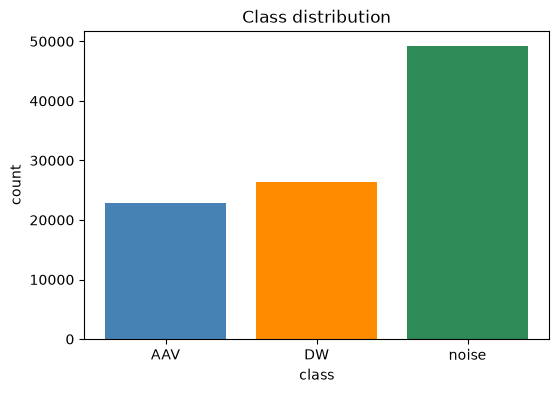

In [4]:
# class counts + proportions
counts = y.value_counts()
props = y.value_counts(normalize=True)

print("counts:")
print(counts)
print("\nproportions:")
print(props.round(4))

print("\nmajority:", counts.idxmax())
print("minority:", counts.idxmin())
print("imbalance ratio (max/min):", round(counts.max() / counts.min(), 2))

# bar chart for class distribution
order = ["AAV", "DW", "noise"]

plt.figure(figsize=(6, 4))
plt.bar(order, [counts[c] for c in order], color=["steelblue", "darkorange", "seagreen"])
plt.title("Class distribution")
plt.ylabel("count")
plt.xlabel("class")
plt.show()


### Feature description
All 100 features (`att_1` to `att_100`) are **numerical**. There are no categorical / text / image columns here.

That means:
- I don't need one-hot encoding
- I probably should still scale the features for Logistic Regression
- Feature selection might help because 100 features is a lot and some might be noisy or redundant

## 2. EDA (Exploratory Data Analysis)

Before modeling I want to understand the data a bit: shape, missing values, basic stats, distributions, outliers, and correlations.


In [5]:
# basic shape / dtypes
print("shape:", X.shape)
print(X.dtypes.value_counts())

# descriptive stats for a few features (printing all 100 is too much)
X.iloc[:, :8].describe()


shape: (98528, 100)
float64    100
Name: count, dtype: int64


,att_1,att_2,att_3,att_4,att_5,att_6,att_7,att_8
count,98528.000000,98528.000000,98528.000000,98528.000000,98528.000000,98528.000000,98528.000000,98528.000000
mean,0.131646,0.247174,0.151809,0.184377,0.311614,0.245011,0.237346,0.137759
std,0.325017,0.392819,0.287985,0.305169,0.397819,0.362844,0.366265,0.283256
min,-0.598799,-0.649137,-0.682404,-0.644352,-0.578361,-0.440639,-0.531891,-0.513833
25%,-0.045894,-0.027796,-0.022869,-0.012915,-0.000548,-0.005215,-0.014449,-0.022369
50%,-0.015362,0.035832,0.025195,0.047766,0.107684,0.064902,0.048092,0.010534
75%,0.163623,0.463135,0.212652,0.248913,0.602620,0.355411,0.348597,0.151755
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### Missing values and duplicates
Checking if I need imputation or if I should drop duplicate rows.


In [6]:
missing = X.isna().sum().sum()
dups = X.duplicated().sum()

print("total missing values:", missing)
print("duplicate rows:", dups)


total missing values: 0
duplicate rows: 28


The dataset has no missing values. I found 28 duplicate rows. I am keeping them for now because identical sensor measurements can occur naturally; I cannot tell from the feature values alone whether they are erroneous duplicates.

### Feature distributions
I am plotting a few features just to see what they look like (not all 100).


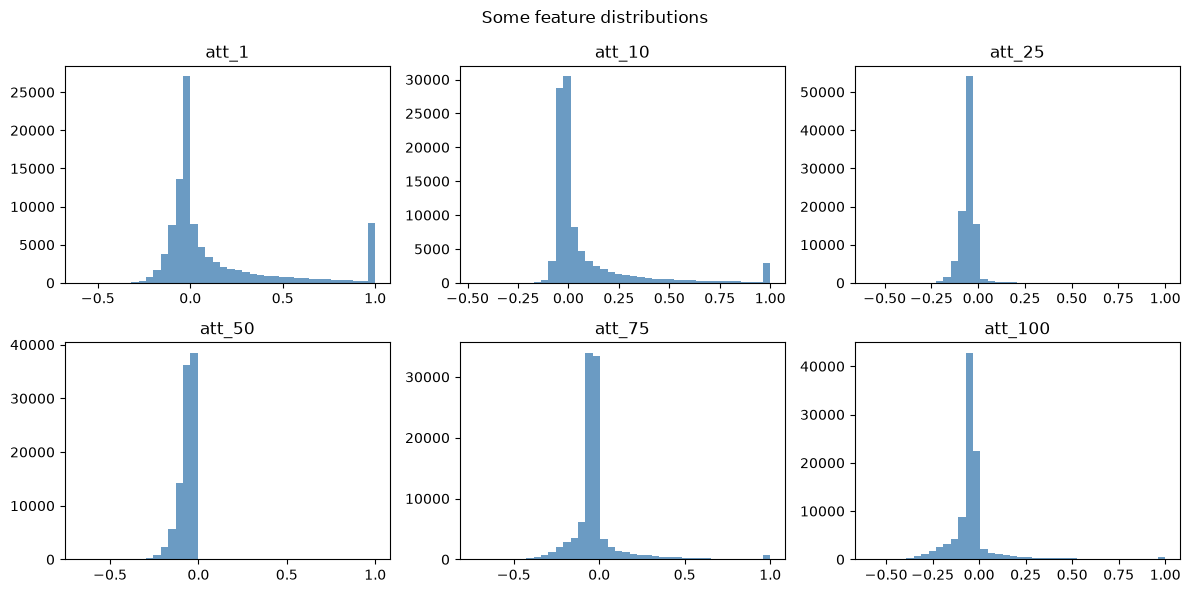

In [7]:
cols_to_plot = ["att_1", "att_10", "att_25", "att_50", "att_75", "att_100"]

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes = axes.ravel()

for i, col in enumerate(cols_to_plot):
    axes[i].hist(X[col], bins=40, color="steelblue", alpha=0.8)
    axes[i].set_title(col)

plt.suptitle("Some feature distributions")
plt.tight_layout()
plt.show()


The features are continuous and not all shaped the same. Some look more skewed than others. I think scaling still makes sense for the linear model.


### Quick outlier check (IQR)
I am not going to delete outliers right away, because weird sensor values might actually be useful for classification. I just want to see how common they are.


In [8]:
def outlier_frac(col):
    q1 = col.quantile(0.25)
    q3 = col.quantile(0.75)
    iqr = q3 - q1
    if iqr == 0:
        return 0
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    return ((col < low) | (col > high)).mean()

outlier_rates = X.apply(outlier_frac)
print(outlier_rates.describe())
print("features with >5% outliers:", (outlier_rates > 0.05).sum())


count    100.000000
mean       0.144404
std        0.084540
min        0.000000
25%        0.056717
50%        0.142797
75%        0.218562
max        0.272785
dtype: float64
features with >5% outliers: 81


Some features have a decent number of IQR outliers. For now I am keeping all rows and letting the models handle it (especially Random Forest is usually okay with this).


### Correlation
Plotting correlation for all 100 features would be huge, so I only use the first 20.


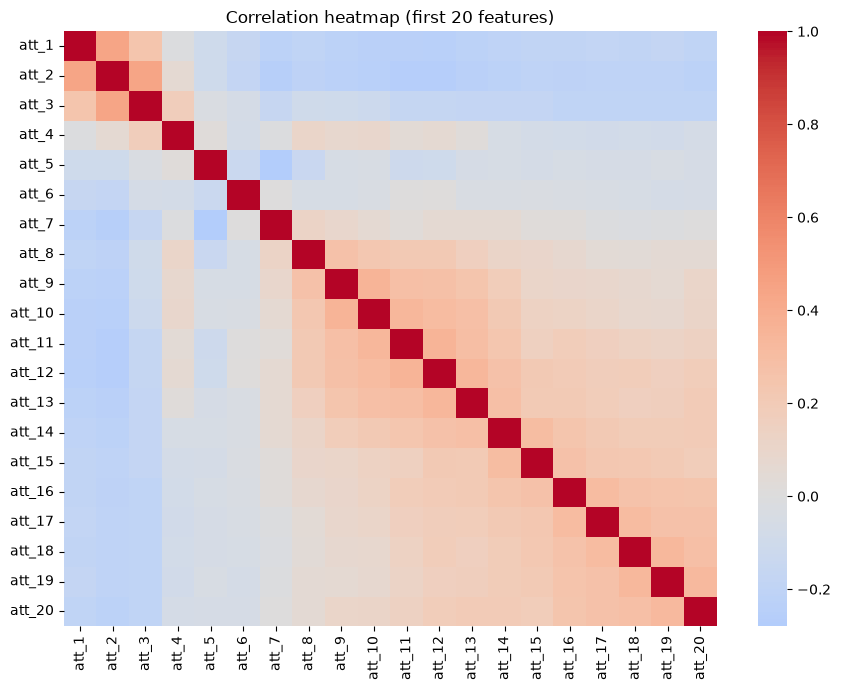

max |correlation| among first 20 features: 0.44


In [9]:
corr = X.iloc[:, :20].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation heatmap (first 20 features)")
plt.tight_layout()
plt.show()

# what's the strongest correlation in this subset? (ignore diagonal)
corr_abs = corr.abs().to_numpy().copy()
np.fill_diagonal(corr_abs, 0)
print("max |correlation| among first 20 features:", round(corr_abs.max(), 3))


There is some correlation between features, which makes sense for sensor channels. This is one reason I want to do feature selection later.


### Do classes look different on high-variance features?
I picked the 8 features with highest variance and compared their average value by class.


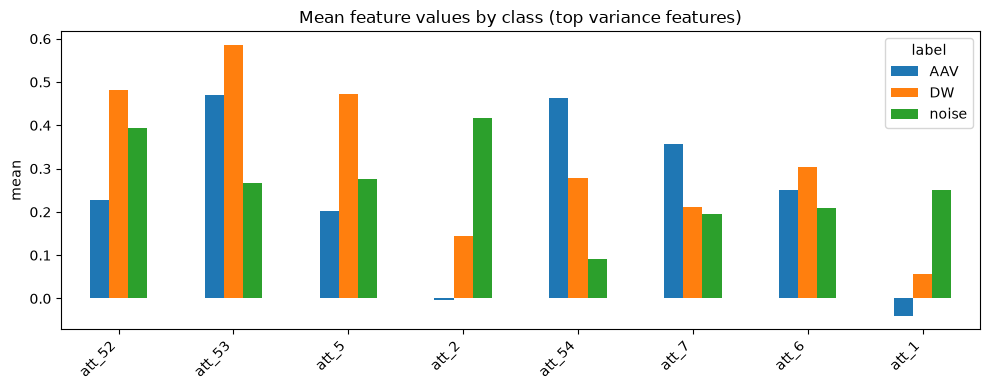

In [10]:
top_feats = X.var().sort_values(ascending=False).head(8).index.tolist()
temp = X.copy()
temp["label"] = y.values

means = temp.groupby("label")[top_feats].mean().loc[order]
means.T.plot(kind="bar", figsize=(10, 4))
plt.title("Mean feature values by class (top variance features)")
plt.ylabel("mean")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


From this plot, at least some features have different averages across AAV / DW / noise, so classification should be possible.


## 3. Data Preprocessing

The input features are numerical, so categorical encoding is unnecessary. There are no missing values to impute. I found 28 duplicate rows and am keeping them for now, because repeated sensor readings are not necessarily data errors.

I will standardize features for Logistic Regression, but not for Random Forest. I use a stratified split to maintain similar class proportions. Preprocessing and feature selection are fitted on the training data only.

In [11]:
# encode string labels to numbers for sklearn
le = LabelEncoder()
y_enc = le.fit_transform(y)
print("classes:", list(le.classes_))
print("encoded example:", y_enc[:10])


classes: ['AAV', 'DW', 'noise']
encoded example: [0 1 1 2 1 2 1 2 2 1]


### Train/test split
I am using an 80/20 split with stratification so each split keeps a similar class ratio. 80/20 is pretty standard and still leaves a large test set (~20k rows).


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_enc
)

print("train size:", X_train.shape)
print("test size:", X_test.shape)

# quick check that stratification worked
print("\ntrain class proportions:")
print(pd.Series(y_train).value_counts(normalize=True).sort_index().round(4))
print("test class proportions:")
print(pd.Series(y_test).value_counts(normalize=True).sort_index().round(4))


train size: (78822, 100)
test size: (19706, 100)

train class proportions:
0    0.2318
1    0.2682
2    0.5000
Name: proportion, dtype: float64
test class proportions:
0    0.2318
1    0.2682
2    0.5000
Name: proportion, dtype: float64


## 4. Feature Engineering / Feature Selection

I did not create a bunch of new hand-crafted features here because the dataset already gives 100 regenerated sensor attributes. Instead I focus on **feature selection**.

### Method I chose: SelectKBest with ANOVA F (`f_classif`)
(Only one method, as required.)

**How it works (my understanding):**  
It looks at each feature one by one and computes an F-score for how related that feature is to the class label. Then it keeps the top k features with the highest scores.

**Why this one:**  
It is simple, fast on a big dataset, and easy to explain. Also I can show which features got selected vs removed.


kept: 40
removed: 60
top 10 features by ANOVA F-score:
att_51    20187.35
att_2     10372.45
att_54     7498.83
att_1      6800.96
att_43     6676.78
att_41     6522.29
att_42     6460.21
att_44     6445.00
att_45     6429.13
att_47     6321.42
Name: F_score, dtype: float64


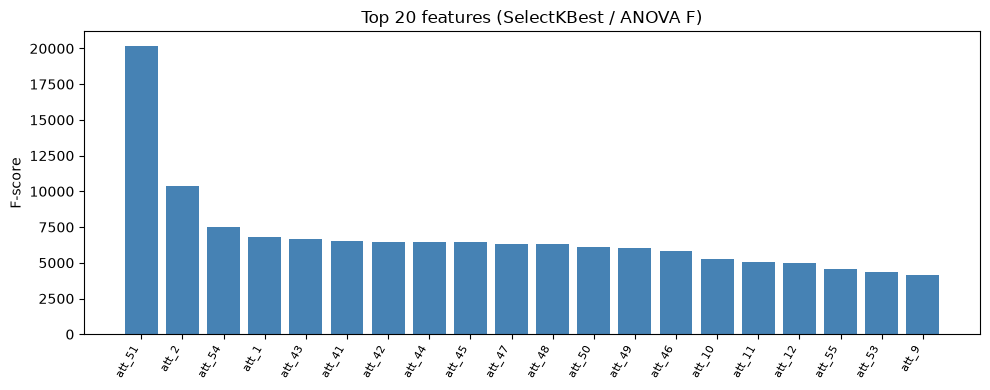

lowest F-score features (examples of removed ones):
att_99     71.38
att_100    75.90
att_95     78.24
att_98     82.58
att_96     87.04
Name: F_score, dtype: float64


In [13]:
# start with k=40, later tuning can change k
K_BEST = 40

selector = SelectKBest(score_func=f_classif, k=K_BEST)
selector.fit(X_train, y_train)  # fit on train only so I don't leak test info

scores = pd.Series(selector.scores_, index=X.columns, name="F_score")
selected = X.columns[selector.get_support()].tolist()
removed = X.columns[~selector.get_support()].tolist()

print("kept:", len(selected))
print("removed:", len(removed))

# top features by F score
print("top 10 features by ANOVA F-score:")
print(scores.sort_values(ascending=False).head(10).round(2))

# plot top 20 F-scores
top20 = scores.sort_values(ascending=False).head(20)

plt.figure(figsize=(10, 4))
plt.bar(range(len(top20)), top20.values, color="steelblue")
plt.xticks(range(len(top20)), top20.index, rotation=60, ha="right", fontsize=8)
plt.ylabel("F-score")
plt.title("Top 20 features (SelectKBest / ANOVA F)")
plt.tight_layout()
plt.show()

print("lowest F-score features (examples of removed ones):")
print(scores.sort_values().head(5).round(2))


The features with higher F-scores are the ones that differ more across classes, so keeping those should help. Lower F-score features are more like noise for this task, so dropping them (especially for Logistic Regression) seems reasonable.


## 5. Model Development

I am training **two classification models**:
1. **Logistic Regression** — good baseline, works well after scaling
2. **Random Forest** — can capture non-linear patterns / feature interactions

I put scaler + SelectKBest + model into a `Pipeline` so scaling/selection is fit on training data only.

### Model 1: Logistic Regression
Important parameters I am starting with:
- `C=1.0` → inverse of regularization strength (smaller C = stronger regularization)
- `class_weight="balanced"` → helps a bit with the 1:1:2 imbalance
- `solver="lbfgs"` → works for multi-class
- `max_iter=1000` → just so it has enough iterations to converge


In [14]:
pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif, k=K_BEST)),
    ("clf", LogisticRegression(
        solver="lbfgs",
        max_iter=1000,
        class_weight="balanced",
        C=1.0,
        random_state=RANDOM_STATE
    ))
])

print(pipe_lr)


Pipeline(steps=[('scaler', StandardScaler()), ('select', SelectKBest(k=40)),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])


### Model 2: Random Forest
Starting parameters:
- `n_estimators=150` → number of trees
- `max_depth=20` → limits how deep each tree can go (helps control overfitting)
- `min_samples_leaf=2` → another way to keep trees from getting too specific
- `class_weight="balanced_subsample"` → similar idea as balanced weights


In [15]:
# A tree-based model does not need feature scaling.
pipe_rf = Pipeline([
    ("select", SelectKBest(f_classif, k=K_BEST)),
    ("clf", RandomForestClassifier(
        n_estimators=150,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])
pipe_rf

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('select', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"k k: int or ""all"", default=10Number of top features to select.The ""all"" option bypasses selection, for use in a parameter search.",40
,"score_func score_func: callable, default=f_classifFunction taking two arrays X and y, and returning a pair of arrays(scores, pvalues) or a single array with scores.Default is f_classif (see below ""See Also""). The default function onlyworks with classification tasks... versionadded:: 0.18",<function f_c...x7fd57b75a700>
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",150
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for detail

### Model evaluation

Both models use the same train/test split and metrics, so I use one small function to compare them consistently.

In [16]:
def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    # train
    model.fit(X_tr, y_tr)

    # predictions
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)

    # metrics
    results = {
        "model": name,
        "train_acc": accuracy_score(y_tr, pred_tr),
        "test_acc": accuracy_score(y_te, pred_te),
        "train_macro_f1": f1_score(y_tr, pred_tr, average="macro"),
        "test_macro_f1": f1_score(y_te, pred_te, average="macro"),
    }

    print("====", name, "====")
    print(classification_report(y_te, pred_te, target_names=le.classes_, digits=4))
    return results, pred_te, model


### Train baseline models


==== LogReg baseline ====
              precision    recall  f1-score   support

         AAV     0.7231    0.8376    0.7761      4568
          DW     0.6662    0.8123    0.7320      5285
       noise     0.9262    0.7493    0.8284      9853

    accuracy                         0.7867     19706
   macro avg     0.7718    0.7997    0.7789     19706
weighted avg     0.8094    0.7867    0.7905     19706



==== RF baseline ====
              precision    recall  f1-score   support

         AAV     0.7585    0.9037    0.8248      4568
          DW     0.7625    0.8148    0.7878      5285
       noise     0.9163    0.8014    0.8550      9853

    accuracy                         0.8287     19706
   macro avg     0.8125    0.8399    0.8225     19706
weighted avg     0.8385    0.8287    0.8300     19706



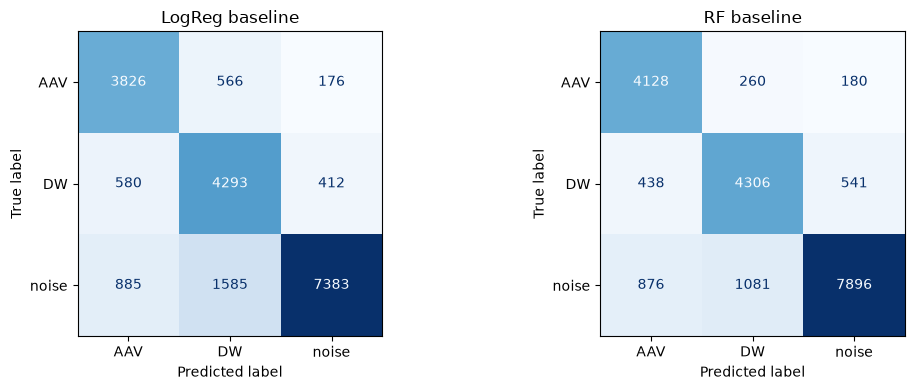

In [17]:
# logistic regression baseline
lr_base_metrics, lr_base_pred, lr_base_model = evaluate(
    "LogReg baseline", pipe_lr, X_train, y_train, X_test, y_test
)

# random forest baseline
rf_base_metrics, rf_base_pred, rf_base_model = evaluate(
    "RF baseline", pipe_rf, X_train, y_train, X_test, y_test
)

# put baseline scores in one table
baseline_df = pd.DataFrame([lr_base_metrics, rf_base_metrics]).round(4)
baseline_df

# confusion matrices for baselines
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, lr_base_pred),
    display_labels=le.classes_
).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("LogReg baseline")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, rf_base_pred),
    display_labels=le.classes_
).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("RF baseline")

plt.tight_layout()
plt.show()


### Comparing all 100 features vs SelectKBest (k=40)

To check whether feature selection helps, I compare the same models and the same train/test split in two settings:
1. all 100 features
2. the top 40 features from SelectKBest

I only change `select__k`. Everything else stays the same.


In [18]:
# same models / same split; only change the number of selected features
fs_rows = []

for model_name, base_pipe in [("LogReg", pipe_lr), ("RF", pipe_rf)]:
    for k_val, setting in [(100, "all 100 features"), (40, "SelectKBest k=40")]:
        model = clone(base_pipe).set_params(select__k=k_val)
        model.fit(X_train, y_train)
        pred_tr = model.predict(X_train)
        pred_te = model.predict(X_test)
        fs_rows.append({
            "model": model_name,
            "features": setting,
            "train_acc": accuracy_score(y_train, pred_tr),
            "test_acc": accuracy_score(y_test, pred_te),
            "train_macro_f1": f1_score(y_train, pred_tr, average="macro"),
            "test_macro_f1": f1_score(y_test, pred_te, average="macro"),
        })

fs_compare = pd.DataFrame(fs_rows).round(4)
fs_compare


,model,features,train_acc,test_acc,train_macro_f1,test_macro_f1
0,LogReg,all 100 features,0.7967,0.7922,0.7898,0.7850
1,LogReg,SelectKBest k=40,0.7903,0.7867,0.7825,0.7789
2,RF,all 100 features,0.9302,0.8338,0.9294,0.8273
3,RF,SelectKBest k=40,0.9448,0.8287,0.9442,0.8225


From the comparison table:
- Logistic Regression test accuracy goes from about 0.787 with 40 features to about 0.792 with all 100 features. Macro F1 also rises a little (about 0.779 → 0.785).
- Random Forest test accuracy goes from about 0.829 with 40 features to about 0.834 with all 100 features. Macro F1 rises a little too (about 0.823 → 0.827).

So for these baseline settings, SelectKBest with k=40 does **not** improve test performance. Using all features is slightly better.

I still keep SelectKBest in the project because:
1. it is the required feature-selection method to demonstrate, and
2. the F-scores help explain which sensor features matter most.

In the baseline pipelines I keep `k=40`. Later hyperparameter tuning is allowed to try other values of `k`.


So far Random Forest looks better than Logistic Regression on the test set. Next I will try hyperparameter tuning.

## 6. Hyperparameter Tuning

I am using **RandomizedSearchCV**.

**Why randomized search instead of full grid search?**  
The training set is large (~79k rows). Trying every combination would take too long for this project. Randomized search tests a random sample of combinations, which is usually good enough and much faster.

To make tuning even more practical, I tune on a stratified subsample of 20,000 training rows, then retrain the best settings on the full training set.


In [19]:
# make a smaller stratified sample just for tuning
TUNING_N = 20000

tune_idx, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=TUNING_N,
    stratify=y_train,
    random_state=RANDOM_STATE
)

X_tune = X_train.iloc[tune_idx]
y_tune = y_train[tune_idx]
print("tuning sample size:", X_tune.shape)

cv_tune = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)


tuning sample size: (20000, 100)


### Tuning Logistic Regression
I am tuning:
- `C` (regularization)
- `select__k` (how many features to keep)

These matter because C controls underfitting/overfitting for LR, and k controls how much information we keep after SelectKBest.


In [20]:
# Use the baseline pipeline as a starting point instead of writing it again.
lr_search = RandomizedSearchCV(
    estimator=clone(pipe_lr).set_params(clf__max_iter=2000),
    param_distributions={
        "select__k": [20, 30, 40, 50, 60],
        "clf__C": np.logspace(-2, 2, 10)
    },
    n_iter=15,
    scoring="f1_macro",
    cv=cv_tune,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
lr_search.fit(X_tune, y_tune)
print("Logistic Regression parameters:", lr_search.best_params_)
print("CV macro F1:", round(lr_search.best_score_, 4))

Logistic Regression parameters: {'select__k': 60, 'clf__C': np.float64(0.21544346900318834)}
CV macro F1: 0.7862


### Tuning Random Forest
I am tuning:
- `n_estimators`
- `max_depth`
- `min_samples_leaf`
- `max_features`
- `select__k`

These control tree complexity / randomness, which has a big effect on overfitting and accuracy.


In [21]:
rf_search = RandomizedSearchCV(
    estimator=clone(pipe_rf),
    param_distributions={
        "select__k": [20, 30, 40, 50, 60],
        "clf__n_estimators": [100, 150, 200, 250],
        "clf__max_depth": [12, 16, 20, 24, None],
        "clf__min_samples_leaf": [1, 2, 4],
        "clf__max_features": ["sqrt", 0.3, 0.5]
    },
    n_iter=15,
    scoring="f1_macro",
    cv=cv_tune,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_search.fit(X_tune, y_tune)
print("Random Forest parameters:", rf_search.best_params_)
print("CV macro F1:", round(rf_search.best_score_, 4))

Random Forest parameters: {'select__k': 60, 'clf__n_estimators': 250, 'clf__min_samples_leaf': 4, 'clf__max_features': 0.3, 'clf__max_depth': 16}
CV macro F1: 0.8162


### Evaluate the tuned models on the full training set

The searches were performed on a smaller training subset to reduce runtime. I take the best parameter settings, then fit both models on the complete training set before testing.

In [22]:
# best_estimator_ already stores the selected pipeline and parameters.
# Clone it so the next fit uses the full training set rather than the tuning subset.
best_lr = clone(lr_search.best_estimator_)
best_rf = clone(rf_search.best_estimator_)

best_k_lr = lr_search.best_params_["select__k"]
best_k_rf = rf_search.best_params_["select__k"]

lr_tuned_metrics, lr_tuned_pred, lr_tuned_model = evaluate(
    "LogReg tuned", best_lr, X_train, y_train, X_test, y_test
)
rf_tuned_metrics, rf_tuned_pred, rf_tuned_model = evaluate(
    "RF tuned", best_rf, X_train, y_train, X_test, y_test
)

tuned_df = pd.DataFrame([lr_tuned_metrics, rf_tuned_metrics]).round(4)
display(tuned_df)

==== LogReg tuned ====
              precision    recall  f1-score   support

         AAV     0.7308    0.8452    0.7839      4568
          DW     0.6717    0.8193    0.7382      5285
       noise     0.9274    0.7508    0.8298      9853

    accuracy                         0.7911     19706
   macro avg     0.7767    0.8051    0.7840     19706
weighted avg     0.8133    0.7911    0.7946     19706



==== RF tuned ====
              precision    recall  f1-score   support

         AAV     0.7591    0.9087    0.8272      4568
          DW     0.7528    0.8414    0.7947      5285
       noise     0.9315    0.7876    0.8535      9853

    accuracy                         0.8301     19706
   macro avg     0.8145    0.8459    0.8251     19706
weighted avg     0.8436    0.8301    0.8316     19706



,model,train_acc,test_acc,train_macro_f1,test_macro_f1
0,LogReg tuned,0.7953,0.7911,0.7883,0.7840
1,RF tuned,0.9022,0.8301,0.9018,0.8251


## 7. Model Evaluation and Comparison

### Metrics I am using
- **Accuracy:** overall percent correct. Easy to understand, but can look good even if minority classes are weak.
- **Macro F1:** averages F1 across classes equally. Better here because noise is about half the data.
- **Confusion matrix / classification report:** to see which classes get confused.


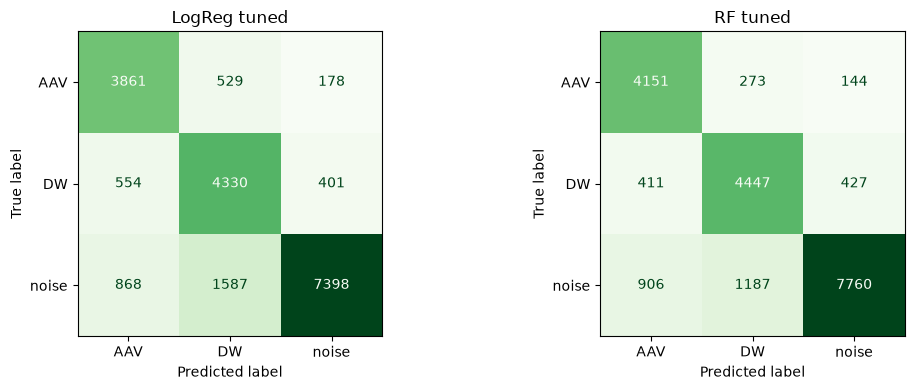

best so far: RF tuned
worst so far: LogReg baseline


In [23]:
# compare baseline vs tuned
comparison = pd.concat([baseline_df, tuned_df], ignore_index=True)
comparison.sort_values("test_macro_f1", ascending=False)

# confusion matrices after tuning
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, lr_tuned_pred),
    display_labels=le.classes_
).plot(ax=axes[0], cmap="Greens", colorbar=False)
axes[0].set_title("LogReg tuned")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, rf_tuned_pred),
    display_labels=le.classes_
).plot(ax=axes[1], cmap="Greens", colorbar=False)
axes[1].set_title("RF tuned")

plt.tight_layout()
plt.show()

best_name = comparison.sort_values("test_macro_f1", ascending=False).iloc[0]["model"]
worst_name = comparison.sort_values("test_macro_f1", ascending=True).iloc[0]["model"]
print("best so far:", best_name)
print("worst so far:", worst_name)


### My comparison notes
Random Forest is doing better than Logistic Regression. I think that is because the sensor features probably have non-linear relationships / interactions, which trees handle better. Logistic Regression is still decent and much simpler.

Tuning helped a little compared to the first baseline settings. The differences are not huge, but macro F1 did improve.


### Overfitting / underfitting check
I compare training and testing **macro F1** for the tuned models.

A large train–test gap can mean overfitting.  
If both scores are low, the model may be underfitting.  
If the scores are close and the test score is still decent, the model is generalizing more reasonably.


In [24]:
# Compare training and testing performance instead of applying a fixed
# threshold to declare whether a model overfits.
gap_df = tuned_df[["model", "train_macro_f1", "test_macro_f1"]].copy()
gap_df["f1_gap"] = gap_df["train_macro_f1"] - gap_df["test_macro_f1"]
display(gap_df.round(4))

,model,train_macro_f1,test_macro_f1,f1_gap
0,LogReg tuned,0.7883,0.7840,0.0043
1,RF tuned,0.9018,0.8251,0.0767


From the table above:
- Tuned Logistic Regression: train macro F1 ≈ 0.788, test macro F1 ≈ 0.784. The gap is only about 0.004, so it generalizes well.
- Tuned Random Forest: train macro F1 ≈ 0.902, test macro F1 ≈ 0.825. The gap is about 0.077, so the forest fits the training data more tightly and looks somewhat overfit compared with Logistic Regression.

Next I try a more regularized Random Forest (smaller `max_depth`, larger `min_samples_leaf`) and check whether that gap shrinks.


In [25]:
# Use the tuned model as the starting point and change just two settings.
rf_reg = clone(best_rf).set_params(
    clf__max_depth=12,
    clf__min_samples_leaf=8
)
rf_reg_metrics, rf_reg_pred, rf_reg_model = evaluate(
    "RF regularized", rf_reg, X_train, y_train, X_test, y_test
)
rf_compare = pd.DataFrame([rf_tuned_metrics, rf_reg_metrics])
rf_compare["f1_gap"] = rf_compare["train_macro_f1"] - rf_compare["test_macro_f1"]
display(rf_compare.round(4))

==== RF regularized ====
              precision    recall  f1-score   support

         AAV     0.7419    0.9074    0.8163      4568
          DW     0.7266    0.8422    0.7801      5285
       noise     0.9416    0.7638    0.8434      9853

    accuracy                         0.8181     19706
   macro avg     0.8033    0.8378    0.8133     19706
weighted avg     0.8376    0.8181    0.8202     19706



,model,train_acc,test_acc,train_macro_f1,test_macro_f1,f1_gap
0,RF tuned,0.9022,0.8301,0.9018,0.8251,0.0767
1,RF regularized,0.8543,0.8181,0.8522,0.8133,0.0389


After reducing `max_depth` to 12 and increasing `min_samples_leaf` to 8:
- the train–test macro F1 gap drops from about 0.077 to about 0.039
- test macro F1 also drops a little (about 0.825 → 0.813)

So regularization reduces overfitting, but there is a small tradeoff in test performance.


In [26]:
comparison = pd.concat([comparison, pd.DataFrame([rf_reg_metrics])], ignore_index=True)
comparison.sort_values("test_macro_f1", ascending=False).round(4)


,model,train_acc,test_acc,train_macro_f1,test_macro_f1
3,RF tuned,0.9022,0.8301,0.9018,0.8251
1,RF baseline,0.9448,0.8287,0.9442,0.8225
4,RF regularized,0.8543,0.8181,0.8522,0.8133
2,LogReg tuned,0.7953,0.7911,0.7883,0.7840
0,LogReg baseline,0.7903,0.7867,0.7825,0.7789


### Cross-validation
I am using **Stratified 5-fold CV** on the training set.

Why stratified 5-fold?
- Keeps class proportions similar in each fold (important because of the 1:1:2 imbalance)
- 5 folds is a common default and not too slow

I want to check whether the single train/test score was just lucky.


In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def run_cv(name, model):
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    print(name)
    print("  fold scores:", np.round(scores, 4))
    print("  mean:", round(scores.mean(), 4), " std:", round(scores.std(), 4))
    return scores

cv_lr = run_cv("LogReg tuned", best_lr)

cv_rf = run_cv("RF tuned", best_rf)

cv_rf_reg = run_cv("RF regularized", rf_reg)

# compare CV mean vs holdout test macro F1
cv_table = pd.DataFrame([
    {
        "model": "LogReg tuned",
        "cv_mean_macro_f1": cv_lr.mean(),
        "cv_std": cv_lr.std(),
        "holdout_macro_f1": lr_tuned_metrics["test_macro_f1"],
    },
    {
        "model": "RF tuned",
        "cv_mean_macro_f1": cv_rf.mean(),
        "cv_std": cv_rf.std(),
        "holdout_macro_f1": rf_tuned_metrics["test_macro_f1"],
    },
    {
        "model": "RF regularized",
        "cv_mean_macro_f1": cv_rf_reg.mean(),
        "cv_std": cv_rf_reg.std(),
        "holdout_macro_f1": rf_reg_metrics["test_macro_f1"],
    },
]).round(4)

cv_table


LogReg tuned
  fold scores: [0.7877 0.7843 0.7871 0.7882 0.7884]
  mean: 0.7871  std: 0.0015


RF tuned
  fold scores: [0.8333 0.8243 0.8285 0.8306 0.8294]
  mean: 0.8292  std: 0.0029


RF regularized
  fold scores: [0.8218 0.8127 0.8161 0.8184 0.8162]
  mean: 0.817  std: 0.003


,model,cv_mean_macro_f1,cv_std,holdout_macro_f1
0,LogReg tuned,0.7871,0.0015,0.7840
1,RF tuned,0.8292,0.0029,0.8251
2,RF regularized,0.8170,0.0030,0.8133


CV scores are close to the holdout scores, so the results seem pretty stable (not just one lucky split).


## 8. Results and Conclusion

### What I learned
1. The SensIT features do contain useful signal for separating AAV / DW / noise.
2. Because noise is the largest class, accuracy alone is not enough — macro F1 is more fair.
3. SelectKBest (ANOVA F) helped me see which sensors matter most, but keeping only 40 features did not beat using all 100 features on the baseline test scores.
4. Random Forest performed better than Logistic Regression overall.
5. Hyperparameter tuning helped a bit.
6. The tuned RF had some overfitting, and making the trees shallower reduced the gap.

### Which model was best?
**Random Forest (tuned)** had the strongest test performance (highest accuracy / macro F1). Logistic Regression was weaker but more stable (almost no train/test gap).

### Did preprocessing / feature selection / tuning matter?
- Scaling + pipeline setup mattered for Logistic Regression.
- Feature selection was useful for interpretation, even though all 100 features scored a bit higher than k=40 in the baseline comparison.
- Tuning improved the models compared to my first manual parameter choices.
- Regularizing RF helped with overfitting, with a small drop in test score.

### Final thoughts
Overall this project worked as a full supervised classification pipeline: understand data → clean/prep → select features → train two models → tune → evaluate with CV. If I had more time I might try gradient boosting or look deeper into which sensor channels are most important for AAV vs DW specifically.


In [28]:
# final comparison table
final_table = comparison.sort_values("test_macro_f1", ascending=False).round(4)
final_table


,model,train_acc,test_acc,train_macro_f1,test_macro_f1
3,RF tuned,0.9022,0.8301,0.9018,0.8251
1,RF baseline,0.9448,0.8287,0.9442,0.8225
4,RF regularized,0.8543,0.8181,0.8522,0.8133
2,LogReg tuned,0.7953,0.7911,0.7883,0.7840
0,LogReg baseline,0.7903,0.7867,0.7825,0.7789
